# 05 — Predicting withdrawal after the first 28 days

**Decision point:** the start of day 28. Rank enrollments that are still active
when the first 28 course days end. One row represents a student in one module
and presentation. The label is final result Withdrawn.

Only positive VLE clicks from days 0–27 enter the feature set. Registration and
unregistration dates define cohort eligibility. They are excluded from the
feature matrix along with student IDs, presentation, module, grades, and
demographics. Enrollments with an unknown registration date or an undated
Withdrawn outcome cannot be placed reliably on the decision timeline and are
excluded from the primary analysis.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.calibration import calibration_curve
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
LAST_DAY = 27
HOLDOUT = '2014J'
RAW = Path('../data/raw')
ASSETS = Path('../assets')
ASSETS.mkdir(exist_ok=True)
KEYS = ['id_student', 'code_module', 'code_presentation']

students = pd.read_csv(RAW / 'studentInfo.csv', usecols=[*KEYS, 'final_result'])
registrations = pd.read_csv(RAW / 'studentRegistration.csv')
cohort = students.merge(registrations, on=KEYS, validate='one_to_one')
assert len(cohort) == len(students) == len(registrations)
cohort['withdrawn'] = cohort['final_result'].eq('Withdrawn').astype(int)
cohort['eligibility'] = np.select(
    [
        cohort['date_registration'].isna(),
        cohort['date_registration'].gt(LAST_DAY),
        cohort['date_unregistration'].le(LAST_DAY),
        cohort['withdrawn'].eq(1) & cohort['date_unregistration'].isna(),
    ],
    ['Registration date missing', 'Registered after cutoff', 'Unregistered by cutoff',
     'Withdrawal date missing'],
    default='Eligible',
)
display(pd.crosstab(cohort['code_presentation'], cohort['eligibility']))
eligible = cohort.loc[cohort['eligibility'].eq('Eligible'), [*KEYS, 'withdrawn']]
assert cohort.loc[eligible.index[eligible['withdrawn'].eq(1)], 'date_unregistration'].gt(LAST_DAY).all()

/Users/i2gunshaker/orca/workspaces/oulad-analytics/goby/oulad-review/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


eligibility,Eligible,Registered after cutoff,Registration date missing,Unregistered by cutoff,Withdrawal date missing
code_presentation,,,,,
2013B,4122,4,8,549,1
2013J,7681,3,10,1149,2
2014B,6506,6,18,1271,3
2014J,9126,5,9,2033,87


In [2]:
window = []
for events in pd.read_csv(
    RAW / 'studentVle.csv', usecols=[*KEYS, 'date', 'id_site', 'sum_click'], chunksize=500_000
):
    window.append(events.loc[events['date'].between(0, LAST_DAY) & events['sum_click'].gt(0)])

activity = pd.concat(window, ignore_index=True)
del window, events
assert activity['date'].between(0, LAST_DAY).all()
assert activity['sum_click'].gt(0).all()

activity['week'] = activity['date'] // 7 + 1
engagement = activity.groupby(KEYS).agg(
    clicks=('sum_click', 'sum'),
    active_days=('date', 'nunique'),
    resources=('id_site', 'nunique'),
)
weekly_clicks = (
    activity.groupby([*KEYS, 'week'])['sum_click'].sum().unstack('week', fill_value=0)
    .reindex(columns=range(1, 5), fill_value=0)
    .add_prefix('clicks_week_')
)
features = engagement.join(weekly_clicks)
data = eligible.merge(features, on=KEYS, how='left', validate='one_to_one')
columns = features.columns.tolist()
data[columns] = data[columns].fillna(0)
del activity

## Temporal evaluation

Train on 2013B, 2013J and 2014B. Use 2014J once as a held-out evaluation
period. Both model configurations are fixed in advance and preprocessing is
fitted on training data. Dates are relative to each course start. Earlier
presentations can finish near the start of the holdout presentation, so this
is a retrospective presentation split. A deployment backtest would also need
to verify when training labels became available.

Returning students can appear on both sides of the split, as in a later
presentation. IDs are used only to report that overlap and to check performance
on previously unseen students.

In [3]:
holdout = data['code_presentation'].eq(HOLDOUT)
train = data.loc[~holdout]
# Sort by enrollment key to make score ties deterministic in the top-k evaluation.
test = data.loc[holdout].sort_values(KEYS)
assert train['code_presentation'].lt(HOLDOUT).all() and HOLDOUT == data['code_presentation'].max()
X_train = np.log1p(train[columns])
X_test = np.log1p(test[columns])
y_train = train['withdrawn']
y_test = test['withdrawn']
unseen = ~test['id_student'].isin(train['id_student'])

display(data.groupby('code_presentation')['withdrawn'].agg(enrollments='size', withdrawn='sum', rate='mean'))
print(f'Train: {len(train):,}. Holdout: {len(test):,}. Holdout enrollments with unseen student IDs: {unseen.sum():,}.')
print(f'Holdout withdrawal prevalence: {y_test.mean():.1%} (also the random-ranking precision baseline).')

models = {
    'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED)),
    'Gradient boosting': GradientBoostingClassifier(
        n_estimators=120, learning_rate=0.05, max_depth=2, random_state=SEED
    ),
}
probabilities = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    probabilities[name] = model.predict_proba(X_test)[:, 1]

,enrollments,withdrawn,rate
code_presentation,,,
2013B,4122,793,0.192382
2013J,7681,1216,0.158313
2014B,6506,1320,0.202890
2014J,9126,1696,0.185843


Train: 18,309. Holdout: 9,126. Holdout enrollments with unseen student IDs: 7,857.
Holdout withdrawal prevalence: 18.6% (also the random-ranking precision baseline).


## Ranking and calibration on the holdout

PR-AUC is reported as average precision (AP), using stepwise precision-recall
integration. Reliability plots show observed and predicted withdrawal rates in
equal-frequency bins. Brier scores measure squared probability error. The models
produce raw probabilities with no post-hoc calibration on the holdout.

The top-risk queue uses the ceiling of 10% of holdout enrollments. Lift is the
precision in that queue divided by overall holdout withdrawal prevalence.
This estimates prioritization yield. Intervention impact would require a study
that measures outcomes under different outreach strategies.

,ROC-AUC,PR-AUC (AP),Brier,Top 10% reviewed,Withdrawals in top 10%,Precision at top 10%,Lift at top 10%,Unseen-student ROC-AUC,Unseen-student PR-AUC (AP)
Model,,,,,,,,,
Logistic regression,0.571,0.218,0.15,913,215,0.235,1.267,0.575,0.203
Gradient boosting,0.563,0.215,0.15,913,202,0.221,1.191,0.563,0.198


Brier score for constant training-prevalence prediction: 0.151


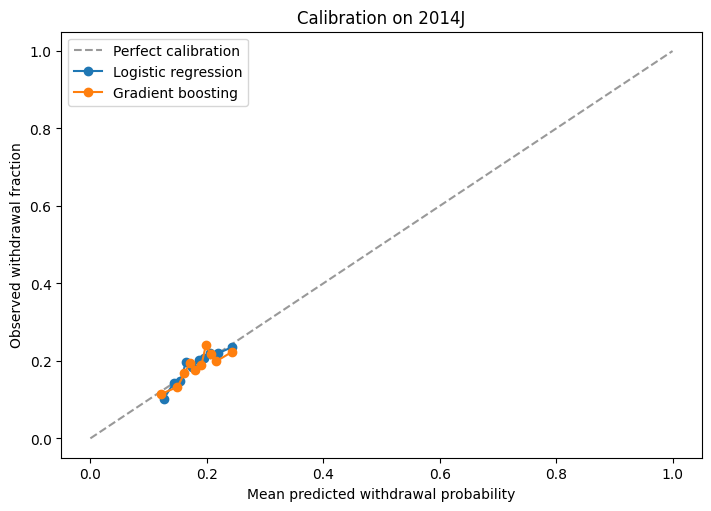

In [4]:
prevalence = y_test.mean()
k = int(np.ceil(0.10 * len(test)))
rows = []
fig, ax = plt.subplots(figsize=(7, 5), layout='constrained')
ax.plot([0, 1], [0, 1], '--', color='0.6', label='Perfect calibration')
for name, probability in probabilities.items():
    top = np.argsort(-probability, kind='stable')[:k]
    withdrawals = int(y_test.iloc[top].sum())
    precision = withdrawals / k
    rows.append({
        'Model': name,
        'ROC-AUC': roc_auc_score(y_test, probability),
        'PR-AUC (AP)': average_precision_score(y_test, probability),
        'Brier': brier_score_loss(y_test, probability),
        'Top 10% reviewed': k,
        'Withdrawals in top 10%': withdrawals,
        'Precision at top 10%': precision,
        'Lift at top 10%': precision / prevalence,
        'Unseen-student ROC-AUC': roc_auc_score(y_test.loc[unseen], probability[unseen]),
        'Unseen-student PR-AUC (AP)': average_precision_score(y_test.loc[unseen], probability[unseen]),
    })
    observed, expected = calibration_curve(y_test, probability, n_bins=10, strategy='quantile')
    ax.plot(expected, observed, marker='o', label=name)

evaluation = pd.DataFrame(rows).set_index('Model')
display(evaluation.round(3))
reference = np.full(len(test), y_train.mean())
print(f'Brier score for constant training-prevalence prediction: {brier_score_loss(y_test, reference):.3f}')
ax.set(xlabel='Mean predicted withdrawal probability', ylabel='Observed withdrawal fraction',
       title='Calibration on 2014J')
ax.legend()
fig.savefig(ASSETS / '05_withdrawal_calibration.png', dpi=125, bbox_inches='tight')
plt.show()

## SHAP importance

TreeSHAP explains the boosting model on the holdout log-odds scale. The bar chart
averages absolute SHAP values across the holdout. Correlated VLE features can
share attribution. These values describe the fitted predictions.

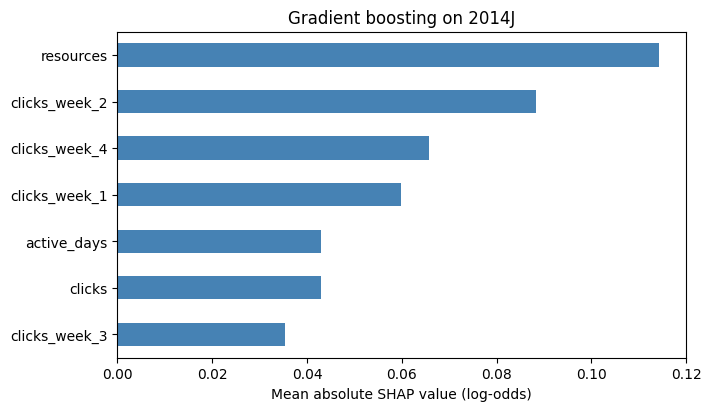

In [5]:
boosting = models['Gradient boosting']
explanation = shap.TreeExplainer(boosting)(X_test)
assert np.allclose(explanation.base_values + explanation.values.sum(axis=1),
                   boosting.decision_function(X_test))
importance = pd.Series(np.abs(explanation.values).mean(axis=0), index=columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
importance.plot.barh(ax=ax, color='steelblue')
ax.set(xlabel='Mean absolute SHAP value (log-odds)', title='Gradient boosting on 2014J')
fig.savefig(ASSETS / '05_withdrawal_shap.png', dpi=125, bbox_inches='tight')
plt.show()

## Interpretation

The held-out ranking estimates what a limited review queue would have captured
in this historical presentation. It applies to enrollments still eligible at
day 28 and excludes withdrawals that already occurred. Missing dates, shifts in
module mix or learner behavior, and the retrospective training label timing
limit what this evaluation establishes about deployment.

In [6]:
for name, row in evaluation.iterrows():
    print(f"{name}: {row['Withdrawals in top 10%']:.0f} of {row['Top 10% reviewed']:.0f} "
          f"enrollments in the review queue withdrew "
          f"({row['Precision at top 10%']:.1%} precision, {row['Lift at top 10%']:.2f}× lift).")

Logistic regression: 215 of 913 enrollments in the review queue withdrew (23.5% precision, 1.27× lift).
Gradient boosting: 202 of 913 enrollments in the review queue withdrew (22.1% precision, 1.19× lift).
